# CA1 – Data Visualisation and Communication
## Employment in AI, Data Science and Software Development in the USA (May 2023)

**Student:** Carlos Eduardo Sabino Accioly Silva – 2023319

**Lecturer:** Taufique Ahmed

**GitHub repository:** https://github.com/CarlosAccioly/Ca1-DataVisu

**Video presentation (4 min):** [to be added]

**Dataset:** U.S. Bureau of Labor Statistics (2024) *Occupational Employment and Wage Statistics, May 2023*. Available at: https://www.bls.gov/oes/tables.htm

In [1]:
   import pandas as pd
   import matplotlib.pyplot as plt
   import seaborn as sns
   import openpyxl
   print("All libraries loaded!")

All libraries loaded!


In [2]:
# Load the May 2023 OEWS dataset (U.S. Bureau of Labor Statistics).
# The Excel file is slow to read, so a local copy (.pkl) is saved the first time
# and reused in later sessions.
import os

if os.path.exists("oews_2023.pkl"):
    df = pd.read_pickle("oews_2023.pkl")
else:
    df = pd.read_excel("all_data_M_2023.xlsx")
    df.to_pickle("oews_2023.pkl")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (413327, 32)


,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [3]:
# 1) Keep national figures only (whole U.S.), all industries combined, detailed occupations
national = df[(df["AREA_TYPE"] == 1) &
              (df["NAICS"] == "000000") &
              (df["O_GROUP"] == "detailed")].copy()

# 2) Occupations related to AI, Data Science and Software Development (SOC codes),
#    grouped into four fields
occupation_groups = {
    "15-1221": "AI & Research",              # Computer and Information Research Scientists
    "15-2051": "Data Science & Analytics",   # Data Scientists
    "15-2041": "Data Science & Analytics",   # Statisticians
    "15-2031": "Data Science & Analytics",   # Operations Research Analysts
    "15-1242": "Data Science & Analytics",   # Database Administrators
    "15-1243": "Data Science & Analytics",   # Database Architects
    "15-1252": "Software Development",       # Software Developers
    "15-1253": "Software Development",       # Software QA Analysts and Testers
    "15-1251": "Software Development",       # Computer Programmers
    "15-1254": "Software Development",       # Web Developers
    "15-1211": "IT Systems & Management",    # Computer Systems Analysts
    "11-3021": "IT Systems & Management",    # Computer and Information Systems Managers
}

tech = national[national["OCC_CODE"].isin(occupation_groups.keys())].copy()
tech["GROUP"] = tech["OCC_CODE"].map(occupation_groups)

# 3) Convert numbers stored as text into real numbers
#    (the BLS uses "*" for missing values and "#" for wages above $239,200)
numeric_cols = ["TOT_EMP", "A_MEAN", "A_MEDIAN", "A_PCT10", "A_PCT25",
                "A_PCT75", "A_PCT90", "H_MEDIAN"]
for col in numeric_cols:
    tech[col] = pd.to_numeric(tech[col], errors="coerce")

tech = tech.sort_values("TOT_EMP", ascending=False)
tech[["OCC_TITLE", "GROUP", "TOT_EMP", "A_MEDIAN"]]

,OCC_TITLE,GROUP,TOT_EMP,A_MEDIAN
149,Software Developers,Software Development,1656880,132270
23,Computer and Information Systems Managers,IT Systems & Management,592600,169510
135,Computer Systems Analysts,IT Systems & Management,498810,103800
150,Software Quality Assurance Analysts and Testers,Software Development,203040,101800
165,Data Scientists,Data Science & Analytics,192710,108020
148,Computer Programmers,Software Development,120370,99700
161,Operations Research Analysts,Data Science & Analytics,117880,83640
151,Web Developers,Software Development,85350,84960
144,Database Administrators,Data Science & Analytics,76140,101510
145,Database Architects,Data Science & Analytics,59920,134700


In [5]:
# One fixed colour per field, used in every chart so the reader can follow each field
group_colors = {
    "AI & Research": "#2a78d6",             # blue
    "Data Science & Analytics": "#eb6834",  # orange
    "Software Development": "#1baf7a",      # green
    "IT Systems & Management": "#eda100",   # yellow
}
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

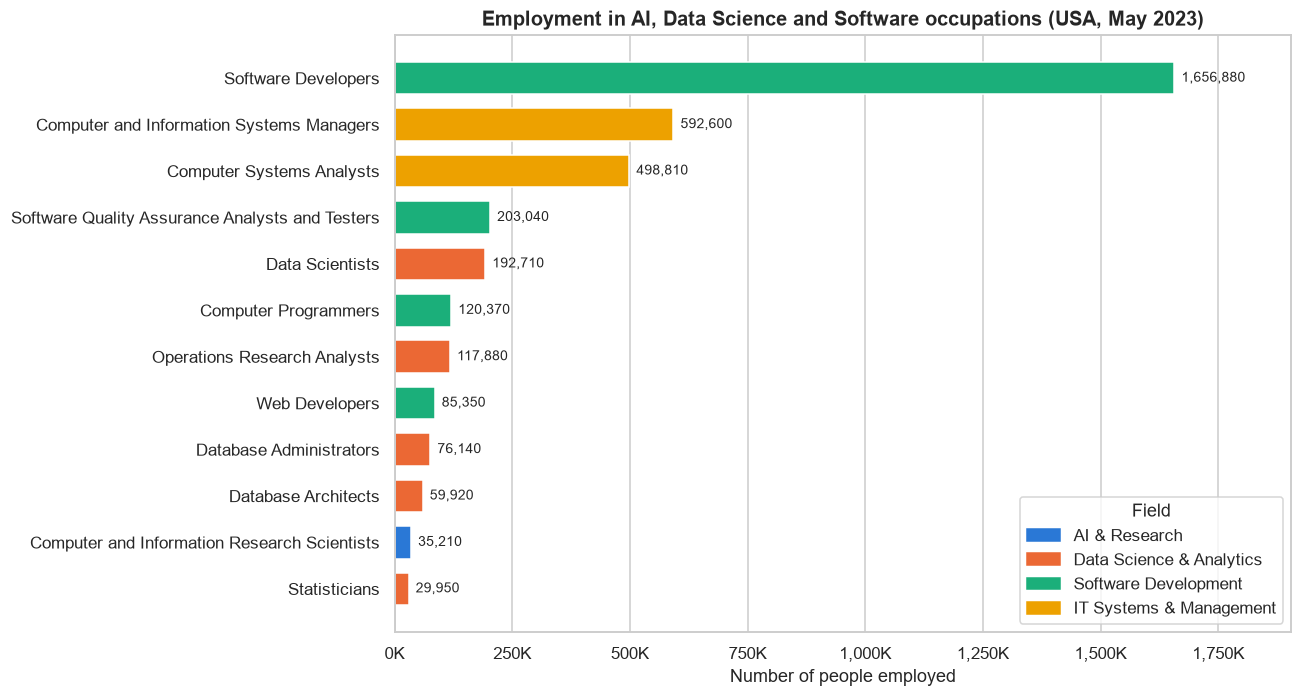

In [6]:
# Visualisation 1: employment by occupation (horizontal bar chart)
chart1 = tech.sort_values("TOT_EMP")   # smallest at the bottom, largest at the top

fig, ax = plt.subplots(figsize=(12, 6.5))
bars = ax.barh(chart1["OCC_TITLE"], chart1["TOT_EMP"],
               color=chart1["GROUP"].map(group_colors), height=0.7)

# Write the number of jobs at the end of each bar
for bar, value in zip(bars, chart1["TOT_EMP"]):
    ax.text(value + 15000, bar.get_y() + bar.get_height() / 2,
            f"{value:,.0f}", va="center", fontsize=9)

ax.set_title("Employment in AI, Data Science and Software occupations (USA, May 2023)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Number of people employed")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x/1000:,.0f}K"))
ax.set_xlim(0, chart1["TOT_EMP"].max() * 1.15)
ax.grid(axis="y", visible=False)

# Legend: one colour per field
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in group_colors.values()]
ax.legend(handles, group_colors.keys(), title="Field", loc="lower right")

plt.tight_layout()
plt.show()

In [7]:
# Key figures used in the explanation below
total = tech["TOT_EMP"].sum()
software_devs = tech.loc[tech["OCC_CODE"] == "15-1252", "TOT_EMP"].iloc[0]
data_scientists = tech.loc[tech["OCC_CODE"] == "15-2051", "TOT_EMP"].iloc[0]

print(f"Total employment in the 12 occupations: {total:,.0f}")
print(f"Software Developers share: {software_devs / total:.1%}")
print(f"Software Developers vs Data Scientists: {software_devs / data_scientists:.1f}x")

Total employment in the 12 occupations: 3,668,860
Software Developers share: 45.2%
Software Developers vs Data Scientists: 8.6x


### Visualisation 1 – Horizontal bar chart: employment by occupation

**Objective:** *Comparison.* To compare how many people work in each of the 12 occupations and identify which roles employ the most people.

**Why this chart type:** The data has one categorical variable (occupation) and one numeric variable (number of employees). A bar chart is the clearest way to compare sizes across categories, because the eye compares bar lengths very accurately. I used horizontal bars so the long occupation names stay readable, and sorted them from largest to smallest so the ranking is visible immediately. Each bar is coloured by field, and the same colours are used in every chart in this notebook.

**What I learned:** Software Developers dominate this group, with 1,656,880 jobs – 45.2% of the 3.67 million jobs across the 12 occupations and about 8.6 times more than Data Scientists (192,710). The occupation most directly linked to AI, Computer and Information Research Scientists, employs only 35,210 people, one of the smallest groups in the chart. The BLS does not have a separate "AI engineer" occupation, so AI work is spread across several categories, mainly research scientists, data scientists and software developers.